# Week 3: Advanced Data Analysis and Visualization in Logistics

## Delivery Performance and Delay Analysis

### Objective

To analyze logistics delivery data using Python, identify patterns in delivery performance, and create visualizations that can support better logistics decision-making.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("../data/cleaned_delivery_data.csv")

data.head()

,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost
0,250.99,delhivery,automobile parts,bike,same day,west,clear,0.999659,0.947595,0.421053,0.272727,no,delivered,0.50,1.000000
1,250.99,xpressbees,cosmetics,ev van,express,central,cold,0.293015,0.956397,0.105263,0.045455,no,delivered,1.00,0.354251
2,250.99,shadowfax,groceries,truck,two day,east,rainy,0.919591,0.536745,0.526316,0.636364,no,delivered,0.75,0.879932
3,250.99,dhl,electronics,ev van,same day,east,cold,0.906644,0.246059,0.315789,0.272727,no,delivered,0.50,0.904915
4,250.99,dhl,clothing,van,two day,north,foggy,0.862351,0.744115,0.473684,0.636364,no,delivered,0.75,0.845054


In [3]:
data.shape

(25000, 15)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   delivery_id          25000 non-null  float64
 1   delivery_partner     25000 non-null  object 
 2   package_type         25000 non-null  object 
 3   vehicle_type         25000 non-null  object 
 4   delivery_mode        25000 non-null  object 
 5   region               25000 non-null  object 
 6   weather_condition    25000 non-null  object 
 7   distance_km          25000 non-null  float64
 8   package_weight_kg    25000 non-null  float64
 9   delivery_time_hours  25000 non-null  float64
 10  expected_time_hours  25000 non-null  float64
 11  delayed              25000 non-null  object 
 12  delivery_status      25000 non-null  object 
 13  delivery_rating      25000 non-null  float64
 14  delivery_cost        25000 non-null  float64
dtypes: float64(7), object(8)
memory usag

In [5]:
data.describe()

,delivery_id,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delivery_rating,delivery_cost
count,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000
mean,12500.500000,0.500138,0.501042,0.328844,0.504895,0.666500,0.500488
std,7212.732314,0.294411,0.294138,0.165312,0.343592,0.287491,0.283473
min,250.990000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6250.750000,0.246337,0.245855,0.210526,0.272727,0.500000,0.257072
50%,12500.500000,0.502215,0.501024,0.315789,0.272727,0.750000,0.502174
75%,18750.250000,0.754003,0.757216,0.421053,0.636364,1.000000,0.743138
max,24750.010000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [6]:
status_counts = data["delivery_status"].value_counts()

print(status_counts)

delivery_status
delivered    18331
delayed       5341
failed        1328
Name: count, dtype: int64


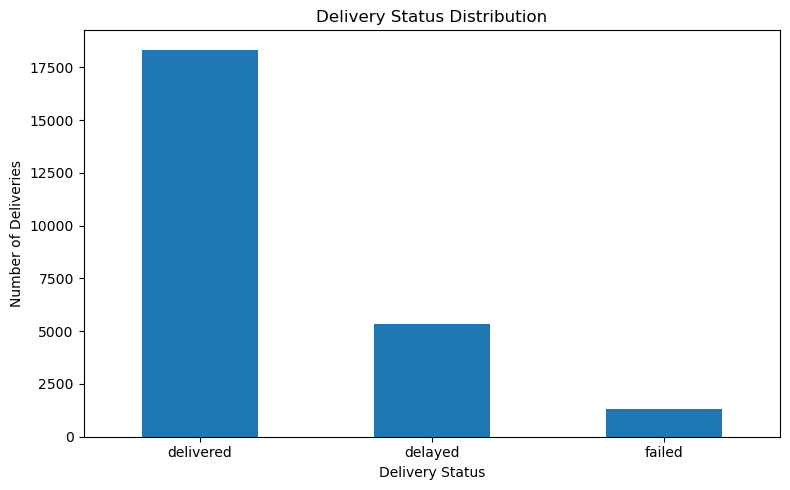

In [7]:
plt.figure(figsize=(8,5))

status_counts.plot(kind="bar")

plt.title("Delivery Status Distribution")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Deliveries")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../visualizations/delivery_status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
weather_delay = pd.crosstab(
    data["weather_condition"],
    data["delayed"],
    normalize="index"
) * 100

weather_delay = weather_delay.rename(
    columns={
        "no": "On Time (%)",
        "yes": "Delayed (%)"
    }
)

print(weather_delay.round(2))

delayed            On Time (%)  Delayed (%)
weather_condition                          
clear                    82.57        17.43
cold                     83.98        16.02
foggy                    69.68        30.32
hot                      82.88        17.12
rainy                    62.65        37.35
stormy                   58.55        41.45


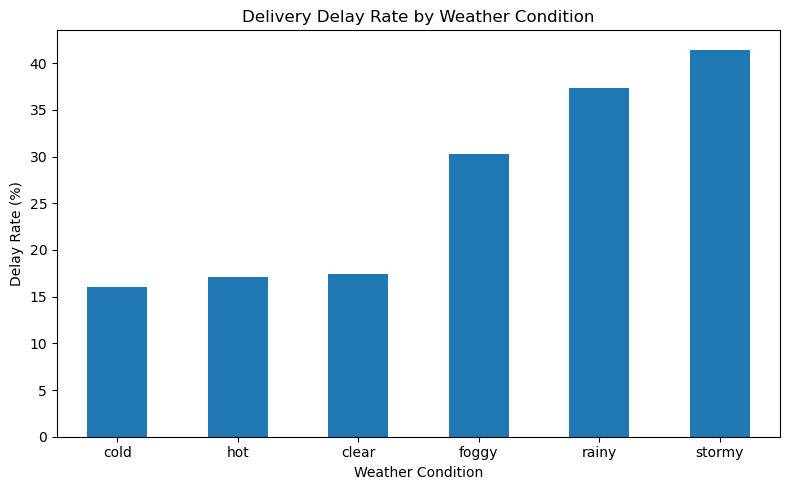

In [9]:
weather_delay["Delayed (%)"].sort_values().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Delivery Delay Rate by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../visualizations/delay_by_weather.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
worst_weather = weather_delay["Delayed (%)"].idxmax()
worst_weather_rate = weather_delay["Delayed (%)"].max()

print("Highest delay weather:", worst_weather)
print("Delay rate:", round(worst_weather_rate, 2), "%")

Highest delay weather: stormy
Delay rate: 41.45 %


In [11]:
vehicle_delay = pd.crosstab(
    data["vehicle_type"],
    data["delayed"],
    normalize="index"
) * 100

vehicle_delay = vehicle_delay.rename(
    columns={
        "no": "On Time (%)",
        "yes": "Delayed (%)"
    }
)

print(vehicle_delay.round(2))

delayed       On Time (%)  Delayed (%)
vehicle_type                          
bike                72.96        27.04
ev bike             73.57        26.43
ev van              73.37        26.63
scooter             73.86        26.14
truck               72.96        27.04
van                 73.23        26.77


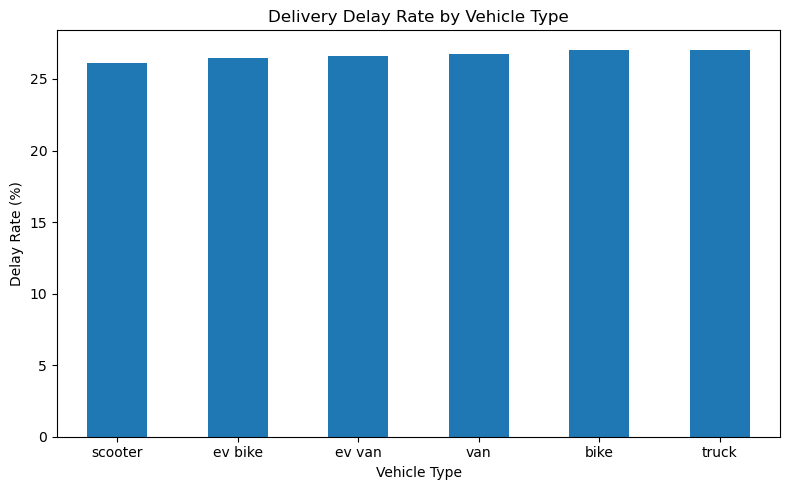

In [12]:
vehicle_delay["Delayed (%)"].sort_values().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Delivery Delay Rate by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../visualizations/delay_by_vehicle.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
worst_vehicle = vehicle_delay["Delayed (%)"].idxmax()
worst_vehicle_rate = vehicle_delay["Delayed (%)"].max()

print("Vehicle with highest delay rate:", worst_vehicle)
print("Delay rate:", round(worst_vehicle_rate, 2), "%")

Vehicle with highest delay rate: truck
Delay rate: 27.04 %


In [14]:
mode_delay = pd.crosstab(
    data["delivery_mode"],
    data["delayed"],
    normalize="index"
) * 100

mode_delay = mode_delay.rename(
    columns={
        "no": "On Time (%)",
        "yes": "Delayed (%)"
    }
)

print(mode_delay.round(2))

delayed        On Time (%)  Delayed (%)
delivery_mode                          
express              26.22        73.78
same day             67.46        32.54
standard            100.00         0.00
two day              99.57         0.43


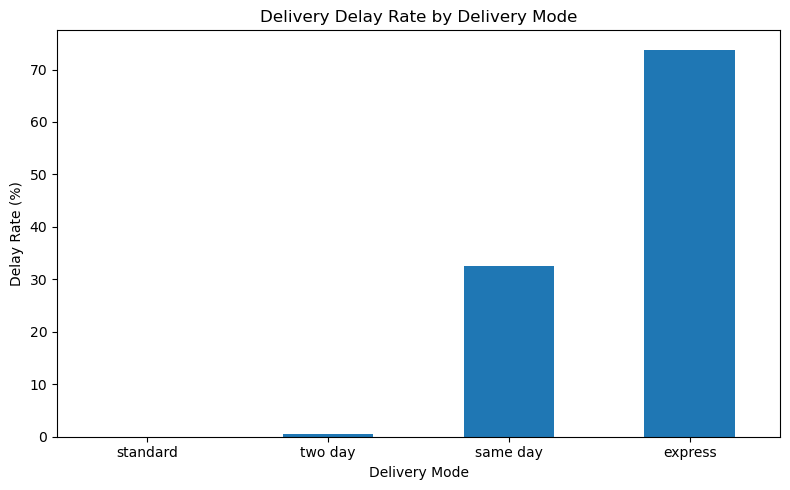

In [15]:
mode_delay["Delayed (%)"].sort_values().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Delivery Delay Rate by Delivery Mode")
plt.xlabel("Delivery Mode")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../visualizations/delay_by_mode.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
region_delay = pd.crosstab(
    data["region"],
    data["delayed"],
    normalize="index"
) * 100

region_delay = region_delay.rename(
    columns={
        "no": "On Time (%)",
        "yes": "Delayed (%)"
    }
)

print(region_delay.round(2))

delayed  On Time (%)  Delayed (%)
region                           
central        72.75        27.25
east           74.20        25.80
north          73.43        26.57
south          73.22        26.78
west           73.05        26.95


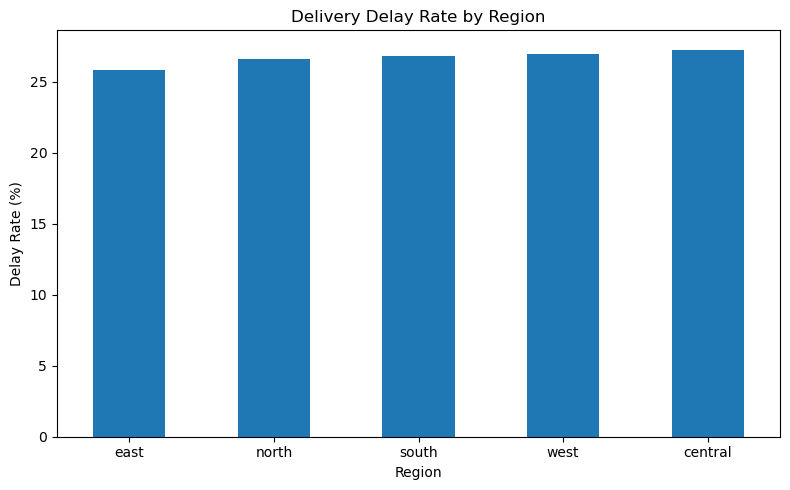

In [17]:
region_delay["Delayed (%)"].sort_values().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Delivery Delay Rate by Region")
plt.xlabel("Region")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../visualizations/delay_by_region.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

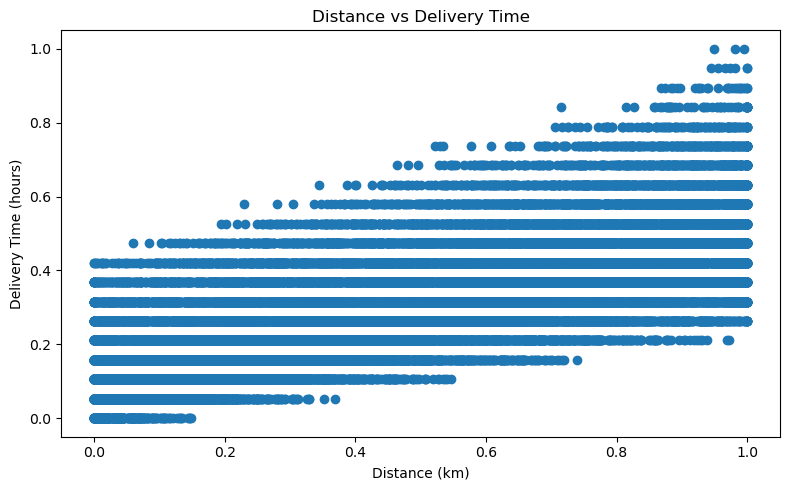

In [18]:
plt.figure(figsize=(8,5))

plt.scatter(
    data["distance_km"],
    data["delivery_time_hours"]
)

plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (hours)")

plt.tight_layout()

plt.savefig(
    "../visualizations/distance_vs_delivery_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
correlation = data[
    ["distance_km", "delivery_time_hours"]
].corr()

print(correlation)

                     distance_km  delivery_time_hours
distance_km             1.000000             0.685883
delivery_time_hours     0.685883             1.000000


In [20]:
cost_by_mode = data.groupby(
    "delivery_mode"
)["delivery_cost"].mean()

print(cost_by_mode.round(2))

delivery_mode
express     0.51
same day    0.54
standard    0.47
two day     0.48
Name: delivery_cost, dtype: float64


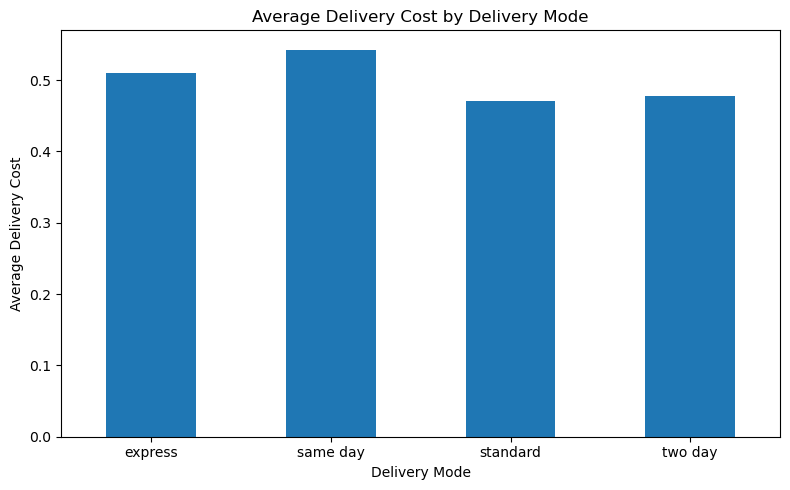

In [21]:
cost_by_mode.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Average Delivery Cost by Delivery Mode")
plt.xlabel("Delivery Mode")
plt.ylabel("Average Delivery Cost")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../visualizations/cost_by_delivery_mode.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

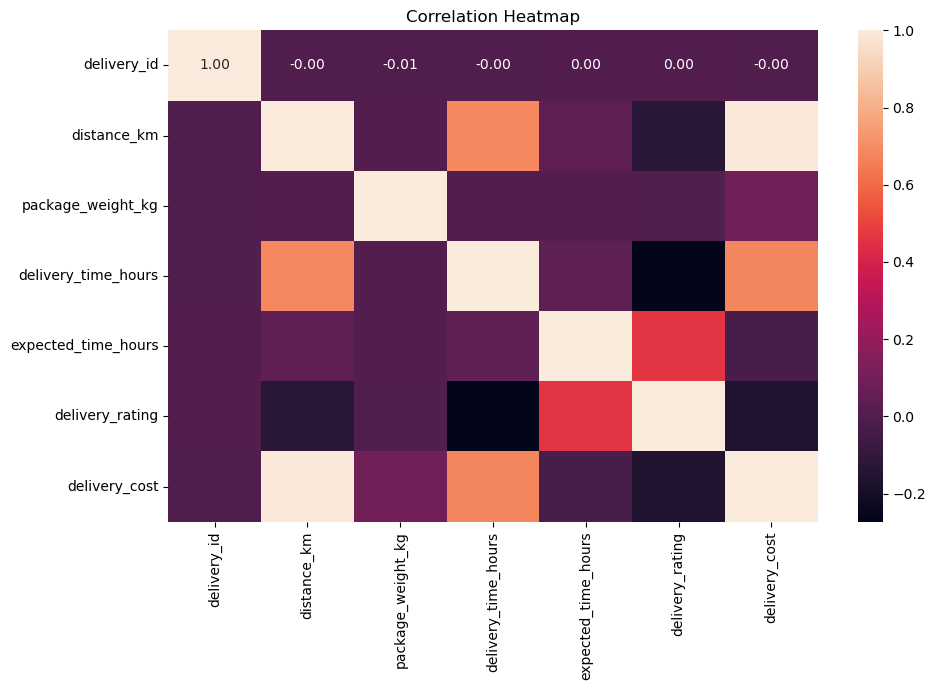

In [22]:
numeric_data = data.select_dtypes(include=np.number)

correlation = numeric_data.corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.savefig(
    "../visualizations/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
print(correlation.round(2))

                     delivery_id  distance_km  package_weight_kg  \
delivery_id                 1.00        -0.00              -0.01   
distance_km                -0.00         1.00               0.00   
package_weight_kg          -0.01         0.00               1.00   
delivery_time_hours        -0.00         0.69               0.00   
expected_time_hours         0.00         0.05               0.00   
delivery_rating             0.00        -0.13              -0.00   
delivery_cost              -0.00         0.99               0.10   

                     delivery_time_hours  expected_time_hours  \
delivery_id                        -0.00                 0.00   
distance_km                         0.69                 0.05   
package_weight_kg                   0.00                 0.00   
delivery_time_hours                 1.00                 0.04   
expected_time_hours                 0.04                 1.00   
delivery_rating                    -0.27                 0.46   


In [25]:
summary = pd.DataFrame({
    "Analysis": [
        "Overall Delay Rate",
        "Highest Weather Delay",
        "Highest Vehicle Delay",
        "Highest Region Delay"
    ],
    "Result": [
        f"{(data['delayed'] == 'yes').mean() * 100:.2f}%",
        worst_weather,
        worst_vehicle,
        region_delay["Delayed (%)"].idxmax()
    ]
})

summary

,Analysis,Result
0,Overall Delay Rate,26.68%
1,Highest Weather Delay,stormy
2,Highest Vehicle Delay,truck
3,Highest Region Delay,central


## Key Findings

1. The overall delivery delay rate was identified from the dataset.
2. Weather conditions showed differences in delivery delay rates.
3. Vehicle types also showed differences in delivery performance.
4. Delivery delay rates varied across regions and delivery modes.
5. Distance and delivery time showed a measurable relationship.
6. Delivery cost varied across different delivery modes.
7. The correlation analysis helped identify relationships between numerical logistics variables.

## Recommendations

- Plan additional delivery time during adverse weather conditions.
- Monitor regions with consistently high delay rates.
- Select suitable vehicle types based on delivery performance.
- Improve scheduling for delivery modes with higher delay rates.
- Use distance and delivery-time information for better route and resource planning.
- Continue using data analysis to improve logistics decision-making.

## Conclusion

The analysis provided useful insights into logistics delivery performance. Different weather conditions, vehicle types, delivery modes, and regions showed variations in delivery delays. The visualizations made these patterns easier to understand, while correlation analysis helped identify relationships between numerical variables. These findings can help logistics companies improve scheduling, resource allocation, and delivery planning.